# LAB 06 — Self-attention
Ví dụ NumPy với embedding minh họa; các vector chưa được huấn luyện.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from attention_numpy import softmax, scaled_dot_product_attention

## 1. Tạo Q, K, V và tính self-attention

In [2]:
tokens = ["I", "like", "cats"]
X = np.array([[1., 0.], [0., 1.], [1., 1.]])
W_Q = np.eye(2)
W_K = np.array([[1., 0.], [0.5, 1.]])
W_V = np.eye(2)

Q, K, V = X @ W_Q, X @ W_K, X @ W_V
scores, weights, context = scaled_dot_product_attention(Q, K, V)
for name, value in [("Q", Q), ("K", K), ("V", V),
                    ("scores", scores), ("weights", weights), ("context", context)]:
    print(f"{name}:\n{np.round(value, 3)}")

Q:
[[1. 0.]
 [0. 1.]
 [1. 1.]]
K:
[[1.  0. ]
 [0.5 1. ]
 [1.5 1. ]]
V:
[[1. 0.]
 [0. 1.]
 [1. 1.]]
scores:
[[0.707 0.354 1.061]
 [0.    0.707 0.707]
 [0.707 1.061 1.768]]
weights:
[[0.32  0.225 0.456]
 [0.198 0.401 0.401]
 [0.188 0.268 0.544]]
context:
[[0.775 0.68 ]
 [0.599 0.802]
 [0.732 0.812]]


## 2. Scaling, temperature và softmax ổn định

In [3]:
raw_scores = Q @ K.T
for name, value in [("Không scaling", raw_scores), ("Có scaling", scores)]:
    print(name, "max weight:", np.round(softmax(value).max(axis=1), 3))

for temperature in (0.5, 1.0, 2.0):
    a = softmax(scores / temperature)
    entropy = -np.sum(a * np.log(a), axis=1).mean()
    print(f"T={temperature}: max={a.max():.3f}, entropy={entropy:.3f}")

print("Softmax [1000, 1001, 1002]:", softmax([1000, 1001, 1002]))

Không scaling max weight: [0.506 0.422 0.629]
Có scaling max weight: [0.456 0.401 0.544]
T=0.5: max=0.734, entropy=0.887
T=1.0: max=0.544, entropy=1.037
T=2.0: max=0.437, entropy=1.083
Softmax [1000, 1001, 1002]: [0.09003057 0.24472847 0.66524096]


## 3. Experiment 1 — Attention distribution
Embedding và query dưới đây chỉ dùng để minh họa phép tính bằng code.

Token              Score  Attention
The                0.766      0.028
movie             -0.389      0.009
was               -0.223      0.010
surprisingly      -0.278      0.010
good               3.647      0.502
despite            2.322      0.134
a                  2.677      0.191
very               1.769      0.077
slow               0.355      0.019
beginning          0.446      0.020
cell_4:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


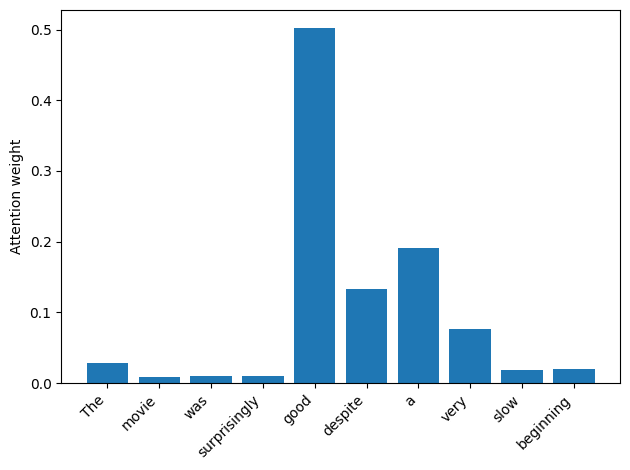

In [4]:
example_tokens = "The movie was surprisingly good despite a very slow beginning".split()
example_vectors = np.random.default_rng(7).normal(size=(len(example_tokens), 4))
query_a = example_vectors[example_tokens.index("good")]
example_scores, example_weights, _ = scaled_dot_product_attention(
    query_a, example_vectors, example_vectors
)
print(f"{'Token':<15} {'Score':>8} {'Attention':>10}")
for token, score, weight in zip(example_tokens, example_scores, example_weights):
    print(f"{token:<15} {score:8.3f} {weight:10.3f}")
plt.bar(example_tokens, example_weights)
plt.ylabel("Attention weight")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 4. Experiment 2 — Cùng sequence, thay đổi query

Query A {'The': 0.028, 'movie': 0.009, 'was': 0.01, 'surprisingly': 0.01, 'good': 0.502, 'despite': 0.134, 'a': 0.191, 'very': 0.077, 'slow': 0.019, 'beginning': 0.02}
cell_5:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
Query B {'The': 0.031, 'movie': 0.296, 'was': 0.13, 'surprisingly': 0.164, 'good': 0.045, 'despite': 0.131, 'a': 0.045, 'very': 0.044, 'slow': 0.074, 'beginning': 0.039}


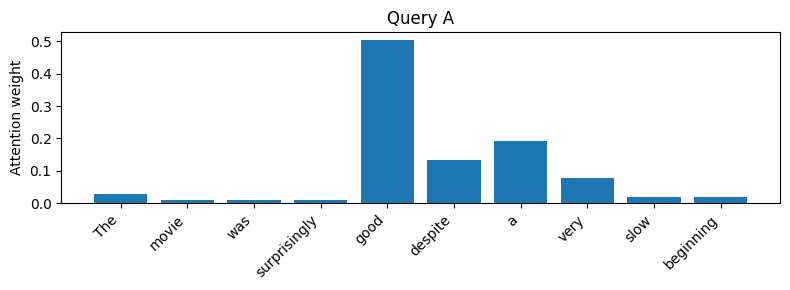

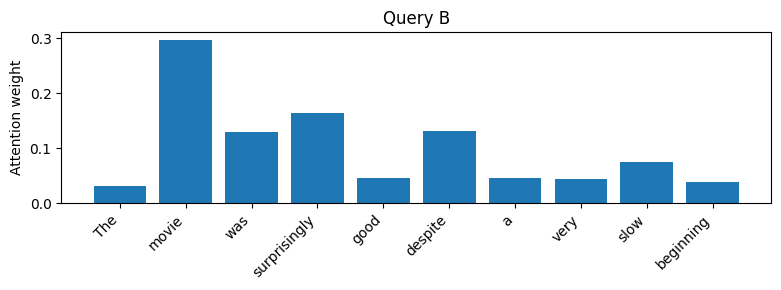

In [5]:
query_b = example_vectors[example_tokens.index("movie")]
for name, query in [("Query A", query_a), ("Query B", query_b)]:
    _, attention, _ = scaled_dot_product_attention(query, example_vectors, example_vectors)
    print(name, dict(zip(example_tokens, np.round(attention, 3))))
    plt.figure(figsize=(8, 3))
    plt.bar(example_tokens, attention)
    plt.ylabel("Attention weight")
    plt.title(name)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 5. Experiment 3 — Heatmap self-attention
Các embedding cố định dưới đây chỉ dùng để quan sát ma trận attention; heatmap không tự chứng minh hiểu ngôn ngữ.

cat {'The': 0.138, 'cat': 0.552, 'that': 0.025, 'I': 0.105, 'adopted': 0.071, 'yesterday': 0.022, 'is': 0.043, 'sleeping': 0.045}
adopted {'The': 0.043, 'cat': 0.033, 'that': 0.014, 'I': 0.023, 'adopted': 0.61, 'yesterday': 0.052, 'is': 0.154, 'sleeping': 0.072}
sleeping {'The': 0.09, 'cat': 0.027, 'that': 0.026, 'I': 0.07, 'adopted': 0.091, 'yesterday': 0.035, 'is': 0.098, 'sleeping': 0.562}
cell_6:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


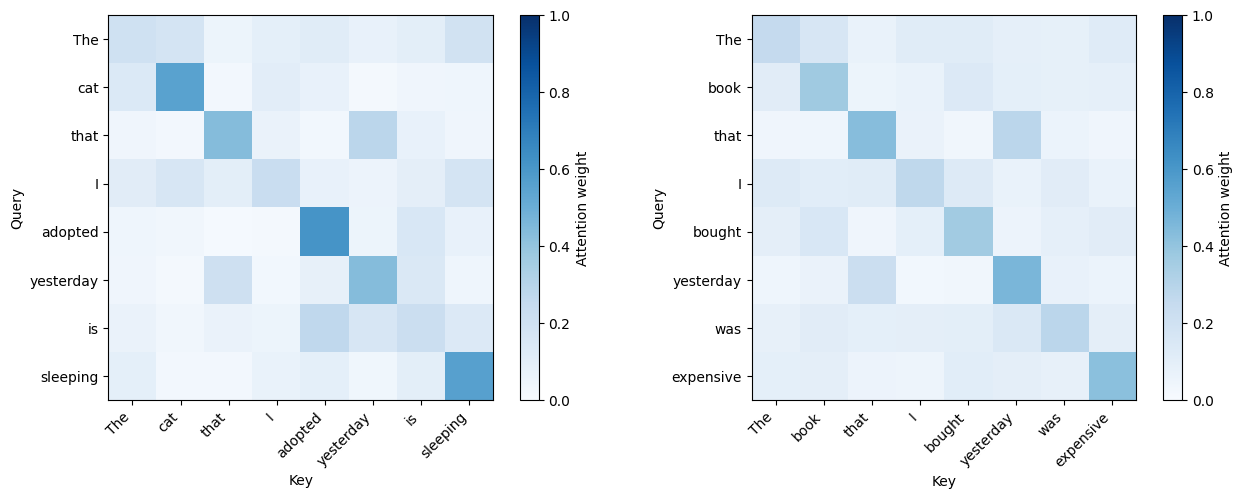

In [6]:
sentences = [
    "The cat that I adopted yesterday is sleeping".split(),
    "The book that I bought yesterday was expensive".split(),
]
rng = np.random.default_rng(42)
vocabulary = sorted({word.lower() for sentence in sentences for word in sentence})
embedding = {word: rng.normal(size=8) for word in vocabulary}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, sentence in zip(axes, sentences):
    X = np.array([embedding[word.lower()] for word in sentence])
    _, attention, _ = scaled_dot_product_attention(X, X, X)
    image = ax.imshow(attention, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(sentence)), sentence, rotation=45, ha="right")
    ax.set_yticks(range(len(sentence)), sentence)
    ax.set_xlabel("Key")
    ax.set_ylabel("Query")
    fig.colorbar(image, ax=ax, label="Attention weight")
    for word in ("cat", "adopted", "sleeping"):
        if word in sentence:
            i = sentence.index(word)
            print(word, dict(zip(sentence, np.round(attention[i], 3))))
plt.tight_layout()
plt.savefig("attention_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Experiment 5 — Kích thước ma trận attention

In [7]:
for length in (10, 100, 500, 1000, 10000):
    print(f"{length} tokens: {length} × {length} = {length ** 2:,} phần tử")

10 tokens: 10 × 10 = 100 phần tử
100 tokens: 100 × 100 = 10,000 phần tử
500 tokens: 500 × 500 = 250,000 phần tử
1000 tokens: 1000 × 1000 = 1,000,000 phần tử
10000 tokens: 10000 × 10000 = 100,000,000 phần tử


## 7. Experiment 4 và application — LSTM so với attention
Dùng lại IMDb 50K, tokenizer, cách chia train/validation/test và cấu hình LAB 05. Cả hai model được huấn luyện lại và đánh giá trên cùng tập test.

In [8]:
import re
import time
from collections import Counter
from pathlib import Path

import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED, VOCAB_SIZE, EMBED, HIDDEN = 42, 10000, 32, 32
MAX_LENGTH, BATCH, EPOCHS = 100, 128, 3
torch.manual_seed(SEED)
torch.set_num_threads(4)

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

candidates = [Path("IMDB Dataset.csv"), Path("../IMDB Dataset.csv"),
              Path.home() / "Downloads/IMDB Dataset.csv"]
dataset_path = next((path for path in candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError("Cần đặt IMDB Dataset.csv trong LaB06, NLP hoặc ~/Downloads")

df = pd.read_csv(dataset_path)
train_df, other = train_test_split(df, test_size=0.2, stratify=df.sentiment, random_state=SEED)
val_df, test_df = train_test_split(other, test_size=0.5, stratify=other.sentiment, random_state=SEED)
train_tokens, val_tokens, test_tokens = [
    [tokenize(text) for text in part.review.fillna("")]
    for part in (train_df, val_df, test_df)
]
vocab = {word: i + 2 for i, (word, _) in enumerate(
    Counter(word for words in train_tokens for word in words).most_common(VOCAB_SIZE - 2)
)}

def encode(token_lists):
    x = np.zeros((len(token_lists), MAX_LENGTH), dtype=np.int64)
    for i, words in enumerate(token_lists):
        ids = [vocab.get(word, 1) for word in words[:MAX_LENGTH]]
        x[i, :len(ids)] = ids
    return torch.tensor(x)

def make_loader(part, token_lists, shuffle=False):
    x = encode(token_lists)
    y = torch.tensor((part.sentiment == "positive").to_numpy(), dtype=torch.float32)
    return DataLoader(TensorDataset(x, y), batch_size=BATCH, shuffle=shuffle)

train_loader = make_loader(train_df, train_tokens, True)
test_loader = make_loader(test_df, test_tokens)
y_test = (test_df.sentiment == "positive").astype(int).to_numpy()
print("Dataset:", dataset_path, "| Train/validation/test:", len(train_df), len(val_df), len(test_df))

Dataset: /Users/user/Downloads/IMDB Dataset.csv | Train/validation/test: 40000 5000 5000


In [9]:
class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab) + 2, EMBED, padding_idx=0)
        self.rnn = nn.LSTM(EMBED, HIDDEN, batch_first=True)
        self.fc = nn.Linear(HIDDEN, 1)

    def forward(self, x):
        out, _ = self.rnn(self.embedding(x))
        last = (x != 0).sum(dim=1).clamp(min=1) - 1
        return self.fc(out[torch.arange(len(x)), last]).squeeze(1)


class AttentionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab) + 2, EMBED, padding_idx=0)
        self.q = nn.Linear(EMBED, HIDDEN)
        self.k = nn.Linear(EMBED, HIDDEN)
        self.v = nn.Linear(EMBED, HIDDEN)
        self.fc = nn.Linear(HIDDEN, 1)

    def forward(self, x, return_attention=False):
        h = self.embedding(x)
        scores = self.q(h) @ self.k(h).transpose(1, 2) / HIDDEN ** 0.5
        mask = x != 0
        weights = scores.masked_fill(~mask[:, None, :], -1e9).softmax(dim=-1)
        context = weights @ self.v(h)
        pooled = (context * mask[:, :, None]).sum(dim=1) / mask.sum(dim=1).clamp(min=1)[:, None]
        logits = self.fc(pooled).squeeze(1)
        return (logits, weights) if return_attention else logits


def train_model(model):
    torch.manual_seed(SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
    loss_fn = nn.BCEWithLogitsLoss()
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        for x, y in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
        print(type(model).__name__, "epoch", epoch + 1)
    return time.perf_counter() - start


def evaluate(model):
    model.eval()
    with torch.no_grad():
        probability = np.concatenate([
            torch.sigmoid(model(x)).numpy() for x, _ in test_loader
        ])
    return (probability >= 0.5).astype(int), probability

LSTMClassifier epoch 1
LSTMClassifier epoch 2
LSTMClassifier epoch 3
AttentionClassifier epoch 1
AttentionClassifier epoch 2
AttentionClassifier epoch 3
    Model  Accuracy    F1  Training time (s)  Parameters
     LSTM     0.697 0.737              17.74      328481
Attention     0.831 0.832              21.19      323201
cell_10:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


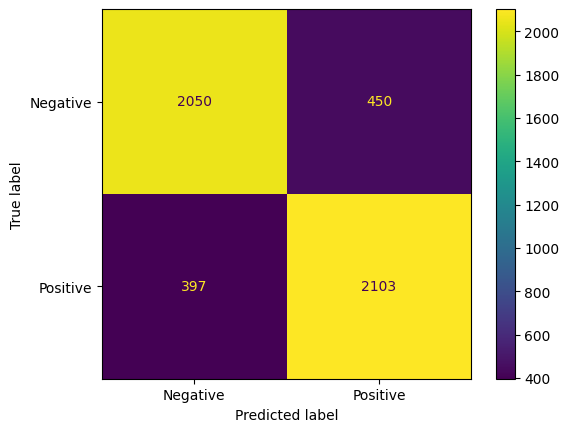

In [10]:
rows = []
for name, model in [("LSTM", LSTMClassifier()), ("Attention", AttentionClassifier())]:
    seconds = train_model(model)
    prediction, probability = evaluate(model)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "F1": f1_score(y_test, prediction),
        "Training time (s)": round(seconds, 2),
        "Parameters": sum(p.numel() for p in model.parameters()),
    })
    if name == "Attention":
        attention_model = model
        attention_pred = prediction
        attention_prob = probability

results = pd.DataFrame(rows)
results.to_csv("results.csv", index=False)
print(results.round(3).to_string(index=False))
ConfusionMatrixDisplay.from_predictions(
    y_test, attention_pred, display_labels=["Negative", "Positive"]
)
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Ba câu sentiment mẫu

I like this movie.
Prediction: negative | P(positive): 0.019
cell_11:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
I do not like this movie.
Prediction: negative | P(positive): 0.009
I thought this movie would be bad, but it was actually excellent.
Prediction: negative | P(positive): 0.039


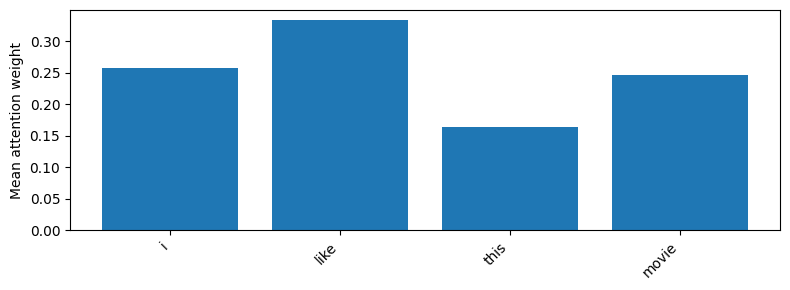

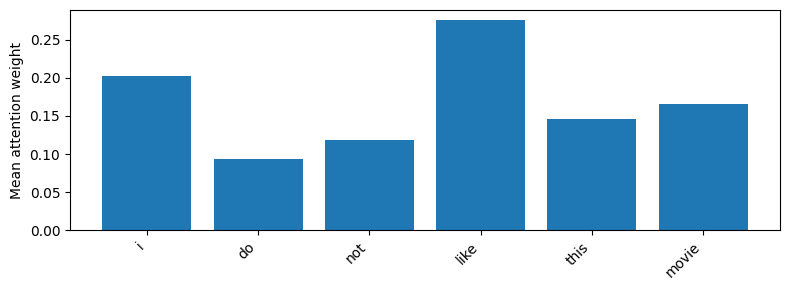

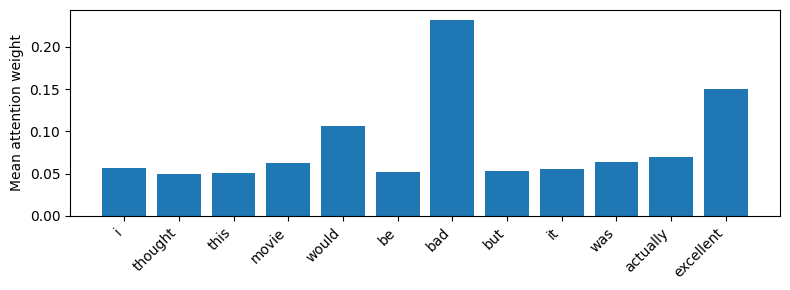

In [11]:
examples = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent.",
]
attention_model.eval()
for sentence in examples:
    words = tokenize(sentence)
    with torch.no_grad():
        logits, weights = attention_model(encode([words]), return_attention=True)
        probability = torch.sigmoid(logits).item()
    importance = weights[0, :len(words), :len(words)].mean(dim=0).numpy()
    print(sentence)
    print("Prediction:", "positive" if probability >= 0.5 else "negative",
          "| P(positive):", round(probability, 3))
    plt.figure(figsize=(8, 3))
    plt.bar(words, importance)
    plt.ylabel("Mean attention weight")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()